# An AMR hierarchy mimicked from the 2048² slice

The three files are not nested refinements of one domain (see `amr_field.ipynb`). Here the **2048² file is the only data**: it is block-averaged into coarser levels, and a quadtree refines only where the field has structure. The result behaves like an AMR mesh: coarse cells in quiet regions, fine cells on the filaments, and a leaf-cell list you could hand to an AMR renderer.

Artifacts are written to `artifacts/amr/` next to this notebook.

In [1]:
import json, csv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path

DATA = Path.home() / 'Downloads' / 'NVB_C009_n2048_z42_temperature_xz_y1024.f32'
OUT = Path('artifacts/amr'); OUT.mkdir(parents=True, exist_ok=True)

a = np.fromfile(DATA, dtype='<f4').reshape(2048, 2048)
L = np.log10(a)                                   # log transform
BAND = L[448:448 + 1152, :]                        # a 16:9 band, 2048 x 1152
print('band', BAND.shape, ' log10 range', BAND.min().round(2), BAND.max().round(2))

band (1152, 2048)  log10 range 3.34 6.04


## 1. A pyramid of coarse levels

Level 0 is the coarsest (64 x 36 cells, 32x32 source pixels each); each next level halves the cell size. Values are block means of the log field.

level 0: 64 x 36 cells, cell = 32 source px
level 1: 128 x 72 cells, cell = 16 source px
level 2: 256 x 144 cells, cell = 8 source px


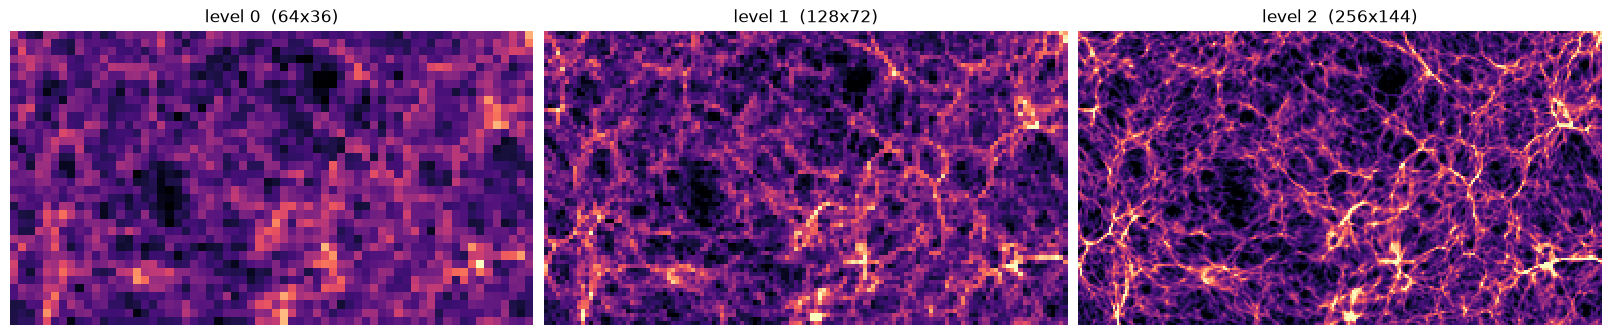

In [2]:
def blocks(x, b):
    h, w = x.shape
    return x.reshape(h // b, b, w // b, b).mean(axis=(1, 3))

P = [blocks(BAND, 32), blocks(BAND, 16), blocks(BAND, 8)]      # 36x64, 72x128, 144x256
for l, p in enumerate(P):
    print(f'level {l}: {p.shape[1]} x {p.shape[0]} cells, cell = {32 >> l} source px')

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
lo, hi = np.percentile(P[2], [2, 99.5])
for ax, p, l in zip(axes, P, range(3)):
    ax.imshow(p, cmap='magma', vmin=lo, vmax=hi, interpolation='nearest'); ax.set_title(f'level {l}  ({p.shape[1]}x{p.shape[0]})'); ax.axis('off')
plt.show()

## 2. The refinement criterion

A cell is worth refining when the finest data inside it varies a lot. For every level-0 cell I take the standard deviation of its level-2 sub-cells; for every level-1 cell, the same over its 2x2 level-2 children. The cells with the largest variation are refined, so the mesh follows the filaments.

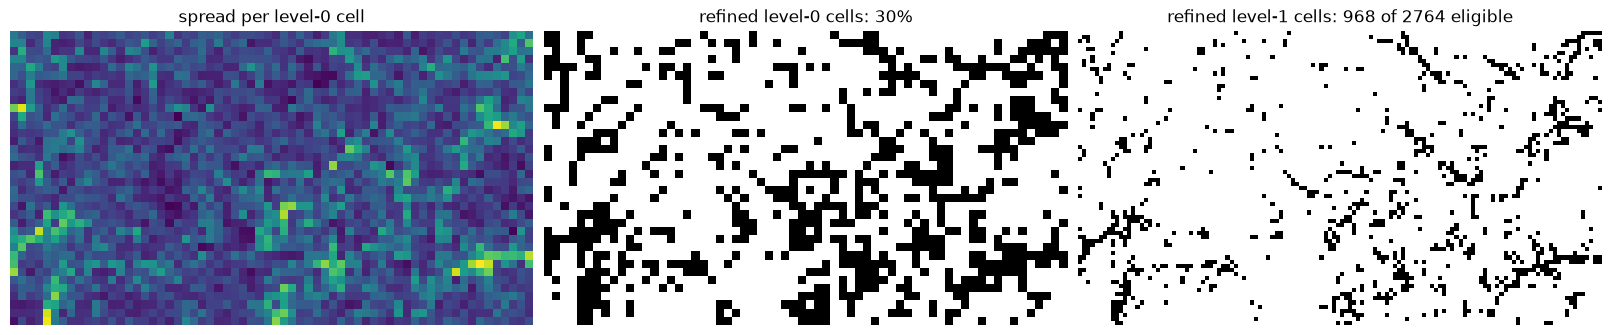

In [3]:
F = P[2]                                                        # the finest level, 144 x 256
s0 = F.reshape(36, 4, 64, 4).std(axis=(1, 3))                   # spread of the 16 sub-cells of each level-0 cell
s1 = F.reshape(72, 2, 128, 2).std(axis=(1, 3))                  # spread of the 4 sub-cells of each level-1 cell

REFINE0 = 0.30      # fraction of level-0 cells refined
REFINE1 = 0.35      # fraction of level-1 children (of refined cells) refined again
t0 = np.quantile(s0, 1 - REFINE0)
ref0 = s0 >= t0                                                  # 36 x 64
eligible1 = np.repeat(np.repeat(ref0, 2, 0), 2, 1)               # level-1 cells inside refined parents
t1 = np.quantile(s1[eligible1], 1 - REFINE1)
ref1 = (s1 >= t1) & eligible1                                    # 72 x 128

fig, axes = plt.subplots(1, 3, figsize=(16, 3.2), constrained_layout=True)
axes[0].imshow(s0, cmap='viridis'); axes[0].set_title('spread per level-0 cell')
axes[1].imshow(ref0, cmap='gray_r'); axes[1].set_title(f'refined level-0 cells: {ref0.mean():.0%}')
axes[2].imshow(ref1, cmap='gray_r'); axes[2].set_title(f'refined level-1 cells: {ref1.sum()} of {eligible1.sum()} eligible')
for ax in axes: ax.axis('off')
plt.show()

## 3. The leaf cells

A level-0 cell that is not refined stays a leaf. A refined one is replaced by four level-1 cells; those that are refined again are replaced by four level-2 cells.

In [4]:
leaves = []   # (level, row, col, value) in that level's own indices
for r in range(36):
    for c in range(64):
        if not ref0[r, c]:
            leaves.append((0, r, c, P[0][r, c])); continue
        for dr in (0, 1):
            for dc in (0, 1):
                r1, c1 = 2 * r + dr, 2 * c + dc
                if not ref1[r1, c1]:
                    leaves.append((1, r1, c1, P[1][r1, c1])); continue
                for er in (0, 1):
                    for ec in (0, 1):
                        r2, c2 = 2 * r1 + er, 2 * c1 + ec
                        leaves.append((2, r2, c2, P[2][r2, c2]))
lv = np.array([l[0] for l in leaves])
full = 144 * 256
print('leaf cells:', len(leaves), ' by level:', np.bincount(lv).tolist())
print(f'uniform finest grid: {full} cells  ->  AMR keeps {len(leaves) / full:.1%}  ({full / len(leaves):.1f}x fewer cells)')

# reconstruction on the finest grid
recon = np.zeros_like(F)
for l, r, c, v in leaves:
    s = 4 >> l
    recon[r * s:(r + 1) * s, c * s:(c + 1) * s] = v
err = recon - F
print(f'error vs the uniform finest level: RMSE {np.sqrt((err**2).mean()):.4f} (log10), max {np.abs(err).max():.3f}')
uni0 = np.kron(P[0], np.ones((4, 4)))
print(f'for comparison, the uniform coarsest level: RMSE {np.sqrt(((uni0 - F)**2).mean()):.4f}  (with {P[0].size} cells)')

leaf cells: 7281  by level: [1613, 1796, 3872]
uniform finest grid: 36864 cells  ->  AMR keeps 19.8%  (5.1x fewer cells)
error vs the uniform finest level: RMSE 0.0792 (log10), max 0.373
for comparison, the uniform coarsest level: RMSE 0.1207  (with 2304 cells)


## 4. The AMR mosaic

Leaf cells coloured by value, outlined by level (white: coarse, cyan: level 1, yellow: level 2).

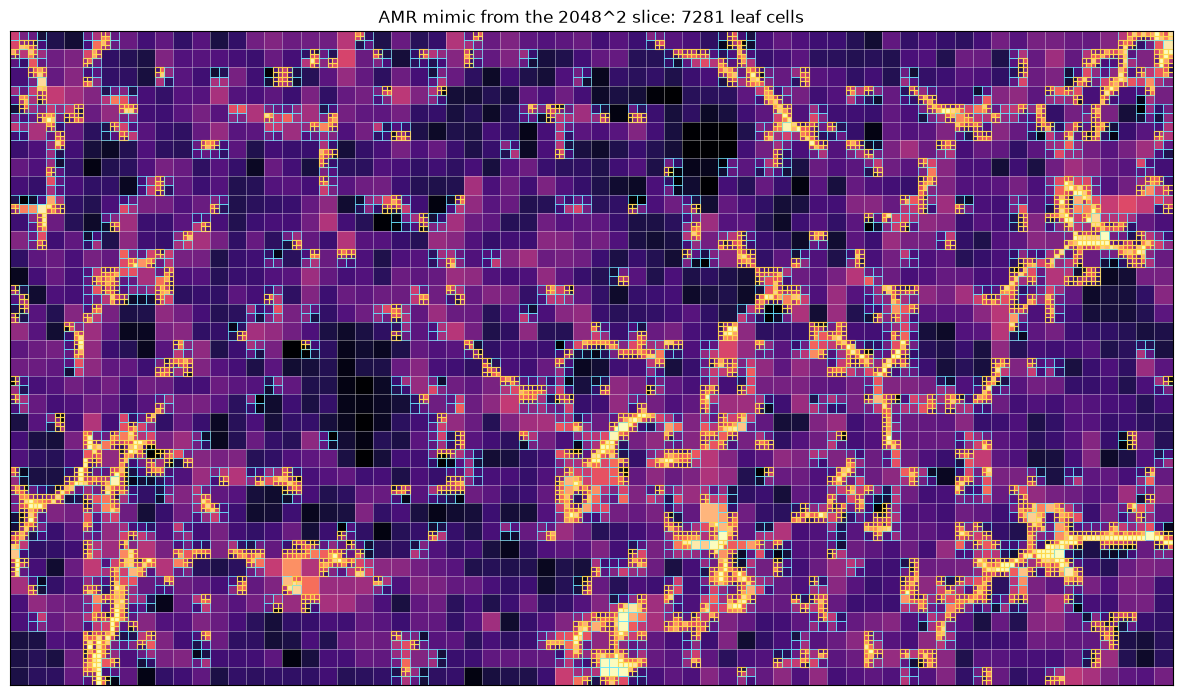

In [5]:
fig, ax = plt.subplots(figsize=(15, 8.5))
ax.imshow(recon, cmap='magma', vmin=lo, vmax=hi, interpolation='nearest', extent=(0, 64, 36, 0))
cols = {0: (1, 1, 1, .35), 1: (.4, .9, 1, .8), 2: (1, .85, .3, .9)}
for l, r, c, v in leaves:
    s = 1 / 2 ** l
    ax.add_patch(Rectangle((c * s, r * s), s, s, fill=False, ec=cols[l], lw=.4 + .2 * l))
ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f'AMR mimic from the 2048^2 slice: {len(leaves)} leaf cells')
fig.savefig(OUT / 'amr_mosaic.png', dpi=140, bbox_inches='tight'); plt.show()

## 5. Side by side with the uniform grids

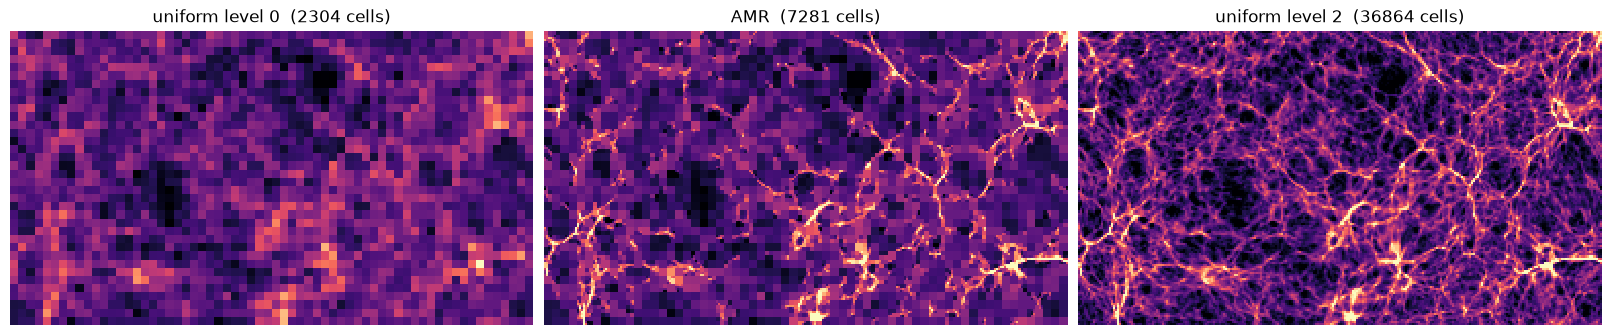

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), constrained_layout=True)
for ax, img, t in ((axes[0], uni0, f'uniform level 0  ({P[0].size} cells)'), (axes[1], recon, f'AMR  ({len(leaves)} cells)'), (axes[2], F, f'uniform level 2  ({F.size} cells)')):
    ax.imshow(img, cmap='magma', vmin=lo, vmax=hi, interpolation='nearest'); ax.set_title(t); ax.axis('off')
fig.savefig(OUT / 'amr_vs_uniform.png', dpi=140, bbox_inches='tight'); plt.show()

## 6. As ASCII

One character per leaf cell, 16 levels on one shared log stretch, drawn at each cell's own size.

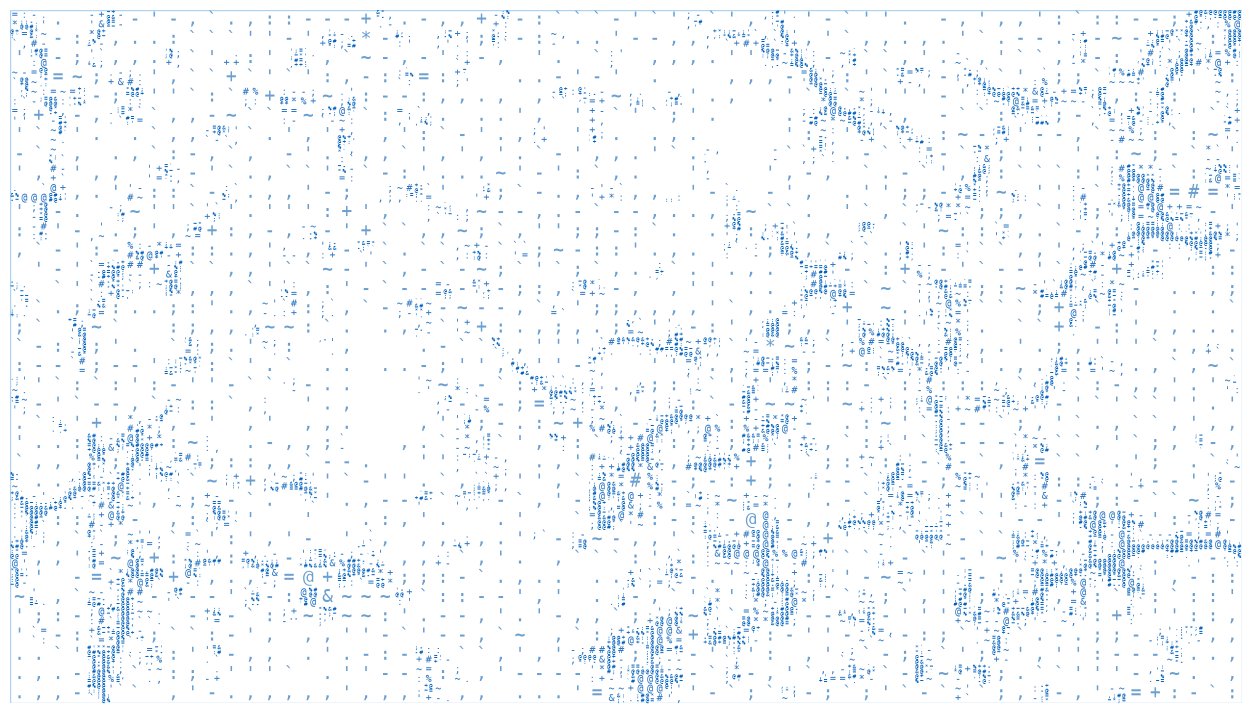

In [7]:
RAMP = " .,'`-:;~+=*#%&@8"
blo, bhi = np.percentile(P[0], [2, 99.5])
glyph = lambda v: min(int(np.clip((v - blo) / (bhi - blo), 0, 1) * 16), 15)

fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(0, 64); ax.set_ylim(36, 0); ax.set_aspect(1); ax.axis('off')
for l, r, c, v in leaves:
    s = 1 / 2 ** l
    ch = RAMP[glyph(v)]
    if ch == ' ':
        continue
    ax.text((c + .5) * s, (r + .5) * s, ch, ha='center', va='center', fontsize=[13, 7.5, 4][l], family='monospace', color=['#6a9fd0', '#2f78c4', '#0061bf'][l])
ax.add_patch(Rectangle((0, 0), 64, 36, fill=False, ec='#add3f1'))
fig.savefig(OUT / 'amr_ascii.png', dpi=140, bbox_inches='tight'); plt.show()

## 7. Export the artifacts

In [8]:
# 1. the leaf list
with open(OUT / 'amr_cells.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['level', 'row', 'col', 'log10_temperature', 'glyph'])
    for l, r, c, v in leaves: w.writerow([l, r, c, round(float(v), 5), RAMP[glyph(v)]])

# 2. the web payload: one grid per level, a hex digit per leaf, '-' where the cell is not a leaf at that level
grids = [np.full(p.shape, '-', dtype='<U1') for p in P]
for l, r, c, v in leaves: grids[l][r, c] = '0123456789abcdef'[glyph(v)]
with open(OUT / 'amr_cells.js', 'w') as f:
    f.write('// AMR mimic from the 2048^2 slice; "-" = not a leaf at this level. Built by tools/amr_from_2048.ipynb.\n')
    f.write('window.ASCII_AMR2 = {\n')
    for l, g in enumerate(grids):
        f.write(f'  l{l}: [\n' + ',\n'.join('    "' + ''.join(row) + '"' for row in g) + '\n  ]' + (',\n' if l < 2 else '\n'))
    f.write('}\n')

# 3. a summary
json.dump({'source': DATA.name, 'band_px': list(BAND.shape), 'levels': ['64x36', '128x72', '256x144'],
           'refine_fraction_level0': float(REFINE0), 'refine_fraction_level1': float(REFINE1),
           'leaf_cells': int(len(leaves)), 'leaf_cells_by_level': np.bincount(lv).tolist(),
           'uniform_finest_cells': int(full), 'cell_reduction': round(full / len(leaves), 2),
           'rmse_log10_vs_finest': round(float(np.sqrt((err ** 2).mean())), 5),
           'rmse_log10_uniform_coarse': round(float(np.sqrt(((uni0 - F) ** 2).mean())), 5)},
          open(OUT / 'amr_summary.json', 'w'), indent=2)
for p in sorted(OUT.iterdir()): print(f'{p.stat().st_size / 1024:8.1f} KiB  {p}')

   523.0 KiB  artifacts/amr/amr_ascii.png
   138.3 KiB  artifacts/amr/amr_cells.csv
    49.4 KiB  artifacts/amr/amr_cells.js
   310.3 KiB  artifacts/amr/amr_mosaic.png
     0.4 KiB  artifacts/amr/amr_summary.json
   204.0 KiB  artifacts/amr/amr_vs_uniform.png
